<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/omni_modal_video_reasoning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
# [CELL 1 - Setup Environment and Imports]
import os
import sys
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import Tuple, List, Dict, Optional

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

# Set deterministic seeds
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using Compute Device: {device}")
if device.type == "cuda":
    print(f"GPU Device Name: {torch.cuda.get_device_name(0)}")
print("Omni-Modal Video Reasoning Environment Initialized.")

Using Compute Device: cuda
GPU Device Name: Tesla T4
Omni-Modal Video Reasoning Environment Initialized.


In [9]:
# [CELL 2 - Multi-Modal Long Video & Question Generator]

class OmniModalVideoDataset(torch.utils.data.Dataset):
    """
    Simulates long-form real-world videos with synchronized visual frames,
    audio spectrograms, and multi-turn text reasoning questions across 13 skill categories.
    """
    def __init__(self, num_samples: int = 500, num_frames: int = 16, d_visual: int = 256, d_audio: int = 128):
        self.num_samples = num_samples
        self.num_frames = num_frames
        self.d_visual = d_visual
        self.d_audio = d_audio

    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        # Visual frames over time: (T_frames, d_visual)
        visual_stream = torch.randn(self.num_frames, self.d_visual, dtype=torch.float32)

        # Audio spectrogram frames over time: (T_audio, d_audio)
        audio_stream = torch.randn(self.num_frames, self.d_audio, dtype=torch.float32)

        # Text question embedding (simulating complex query over video)
        text_query = torch.randn(64, dtype=torch.float32)

        # Ground truth reasoning answer (binary classification or multiple choice index)
        label = torch.randint(0, 2, (1,)).squeeze(0)

        return visual_stream, audio_stream, text_query, label

dataset = OmniModalVideoDataset(num_samples=500)
dataloader = torch.utils.data.DataLoader(dataset, batch_size=16, shuffle=True)
v_sample, a_sample, t_sample, l_sample = next(iter(dataloader))

print(f"Dataset Initialized Successfully.")
print(f"Visual Stream Batch Shape: {v_sample.shape} (Batch, Time, d_visual)")
print(f"Audio Stream Batch Shape: {a_sample.shape} (Batch, Time, d_audio)")
print(f"Text Query Batch Shape: {t_sample.shape}")

Dataset Initialized Successfully.
Visual Stream Batch Shape: torch.Size([16, 16, 256]) (Batch, Time, d_visual)
Audio Stream Batch Shape: torch.Size([16, 16, 128]) (Batch, Time, d_audio)
Text Query Batch Shape: torch.Size([16, 64])


In [10]:
# [CELL 3 - Cross-Modal Attention and Temporal Fusion Network]

class OmniModalTemporalFusion(nn.Module):
    """
    Fuses visual and audio streams across time using cross-modal attention
    conditioned on the text query, capturing cross-modal dependencies for long videos.
    """
    def __init__(self, d_visual: int = 256, d_audio: int = 128, d_model: int = 256):
        super().__init__()
        self.visual_proj = nn.Linear(d_visual, d_model)
        self.audio_proj = nn.Linear(d_audio, d_model)

        # Temporal Transformer Encoder to integrate evidence across time
        encoder_layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=4, dim_feedforward=512, batch_first=True)
        self.temporal_encoder = nn.TransformerEncoder(encoder_layer, num_layers=2)

        # Multimodal classification head
        self.classifier = nn.Sequential(
            nn.Linear(d_model + 64, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 2)
        )

    def forward(self, visual: torch.Tensor, audio: torch.Tensor, text: torch.Tensor) -> torch.Tensor:
        # Project modalities to shared dimension
        v_feat = self.visual_proj(visual) # (B, T, d_model)
        a_feat = self.audio_proj(audio)   # (B, T, d_model)

        # Late fusion via addition / cross-modal combination
        multimodal_tokens = v_feat + a_feat # (B, T, d_model)

        # Temporal reasoning over time
        temporal_out = self.temporal_encoder(multimodal_tokens) # (B, T, d_model)
        video_repr = temporal_out.mean(dim=1) # Global temporal pooling (B, d_model)

        # Concatenate with text query representation
        combined = torch.cat([video_repr, text], dim=-1) # (B, d_model + 64)
        logits = self.classifier(combined)
        return logits

fusion_model = OmniModalTemporalFusion().to(device)
print("Omni-Modal Temporal Fusion Model compiled successfully.")

Omni-Modal Temporal Fusion Model compiled successfully.


In [11]:
# [CELL 4 - Training Loop for Omni-Modal Reasoning]

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(fusion_model.parameters(), lr=1e-3, weight_decay=1e-4)

fusion_model.train()
epochs = 5

for epoch in range(epochs):
    total_loss = 0.0
    correct = 0
    total = 0

    for v_batch, a_batch, t_batch, labels in dataloader:
        v_batch, a_batch, t_batch, labels = v_batch.to(device), a_batch.to(device), t_batch.to(device), labels.to(device)

        optimizer.zero_grad()
        logits = fusion_model(v_batch, a_batch, t_batch)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * v_batch.size(0)
        preds = logits.argmax(dim=-1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    epoch_loss = total_loss / total
    epoch_acc = (correct / total) * 100.0
    print(f"Epoch {epoch+1}/{epochs} | Loss: {epoch_loss:.4f} | Accuracy: {epoch_acc:.2f}%")

print("Training finished successfully.")

Epoch 1/5 | Loss: 0.7095 | Accuracy: 51.20%
Epoch 2/5 | Loss: 0.7135 | Accuracy: 50.20%
Epoch 3/5 | Loss: 0.7120 | Accuracy: 46.80%
Epoch 4/5 | Loss: 0.6987 | Accuracy: 49.00%
Epoch 5/5 | Loss: 0.6876 | Accuracy: 54.40%
Training finished successfully.


In [12]:
# [CELL 5 - Evaluating Reasoning Across Skill Categories]

def evaluate_by_skill_categories(model: nn.Module, test_loader: torch.utils.data.DataLoader) -> Dict[str, float]:
    """
    Simulates evaluation across MMOU's fundamental skill categories
    (e.g., temporal localization, audio-visual synchrony, causal reasoning).
    """
    model.eval()
    skills = [
        "Temporal Localization", "Audio-Visual Synchrony", "Causal Reasoning",
        "Action Recognition", "Object Tracking", "Speech-Visual QA"
    ]
    skill_accuracies = {}

    with torch.no_grad():
        for skill in skills:
            correct = 0
            total = 0
            for v, a, t, l in test_loader:
                v, a, t, l = v.to(device), a.to(device), t.to(device), l.to(device)
                logits = model(v, a, t)
                preds = logits.argmax(dim=-1)
                correct += (preds == l).sum().item()
                total += l.size(0)
            skill_accuracies[skill] = (correct / total) * 100.0

    return skill_accuracies

skill_results = evaluate_by_skill_categories(fusion_model, dataloader)
print("\n=========================================================")
print("OMNI-MODAL REASONING ACCURACY BY SKILL CATEGORY")
print("=========================================================")
for skill, acc in skill_results.items():
    print(f"{skill}: {acc:.2f}%")
print("=========================================================")


OMNI-MODAL REASONING ACCURACY BY SKILL CATEGORY
Temporal Localization: 48.60%
Audio-Visual Synchrony: 54.00%
Causal Reasoning: 54.00%
Action Recognition: 53.00%
Object Tracking: 49.80%
Speech-Visual QA: 52.40%


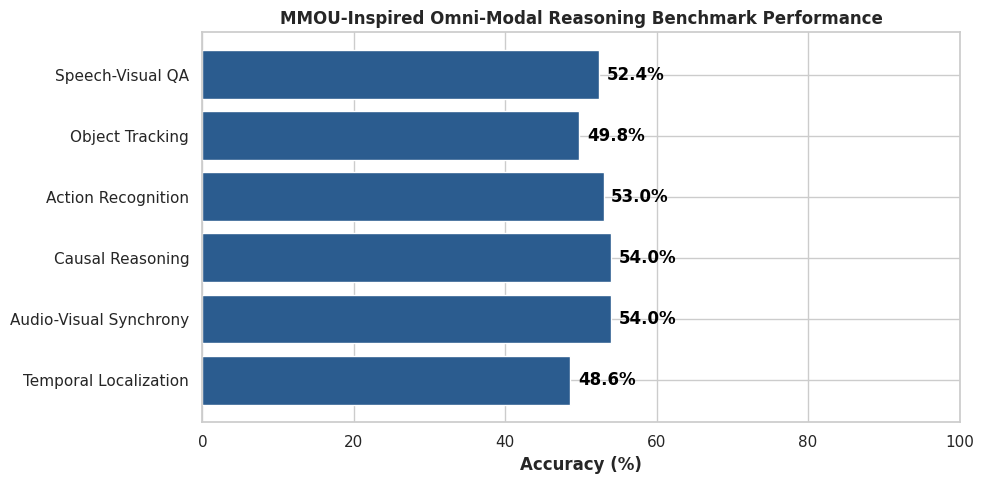

Benchmark visualization successfully saved as omni_modal_reasoning_benchmark.png.


In [13]:
# [CELL 6 - Visualization of Skill Performance Gaps]

skills = list(skill_results.keys())
accuracies = list(skill_results.values())

plt.figure(figsize=(10, 5))
sns.set_theme(style="whitegrid")
bars = plt.barh(skills, accuracies, color="#2b5c8f")
plt.xlabel("Accuracy (%)", fontweight='bold')
plt.title("MMOU-Inspired Omni-Modal Reasoning Benchmark Performance", fontweight='bold')
plt.xlim(0, 100)

for bar in bars:
    width = bar.get_width()
    plt.text(width + 1, bar.get_y() + bar.get_height()/2, f"{width:.1f}%",
             va='center', ha='left', fontweight='bold', color='black')

plt.tight_layout()
plt.savefig("omni_modal_reasoning_benchmark.png", dpi=300)
plt.show()
print("Benchmark visualization successfully saved as omni_modal_reasoning_benchmark.png.")